# Домашнее задание: Ad-hoc 
## Васильева Анна

Содержание:

1. ТЗ по семи вопросам до SQL
2. Ступень глубины
3. Качество данных
4. Масштаб выброса (график 1: доля с доверительным интервалом)
5. Выброс на фоне нормы (график 2: распределение дневной кликабельности)
6. Ошибка трекинга или реальный эффект: проверки, чувствительность, бонус про расход
7. Итоговая справка
8. Ограничения

## 0. Подготовка

Загрузка данных и функций из лекции (`wilson_ci`, `proportion_table`, `period_flag`, `summarize_dq`, `one_pager`). 

In [340]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
import duckdb
from typing import Iterable, Optional, Sequence, Tuple

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def find_data_dir(marker: str = "impressions.csv") -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data" / marker).exists():
            return base / "data"
    for p in here.glob("**/data/" + marker):
        return p.parent
    raise FileNotFoundError("Не найдена папка data/. Откройте ноутбук из распакованной папки adhoc_lecture_handout/.")


DATA = find_data_dir()
con = duckdb.connect()


def register_csv(name: str, filename: str) -> pd.DataFrame:
    df = pd.read_csv(DATA / filename)
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:16s} {len(df):>8,} строк  <- {filename}")
    return df


impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")


def sql(query: str) -> pd.DataFrame:
    return con.execute(query).df()


def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(df, group_cols, success_col, n_col, rate_name="rate"):
    g = df.groupby(list(group_cols), as_index=False).agg(successes=(success_col, "sum"), n=(n_col, "sum"))
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


def period_flag(dates, cutoff, before="before", after="after"):
    d = pd.to_datetime(dates)
    return np.where(d < pd.Timestamp(cutoff), before, after)


def summarize_dq(df, key_cols=None):
    rows = [{"проверка": "строк всего", "значение": len(df)},
            {"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())}]
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({"проверка": f"дубли по ключу: {'+'.join(key_cols)}",
                     "значение": int(df.duplicated(key_cols).sum())})
    return pd.DataFrame(rows)


def one_pager(decision, context, what_done, result, limits, action):
    parts = ["=" * 78, "ИТОГОВАЯ СПРАВКА", "=" * 78, "",
             "Решение:", decision, "",
             "Контекст:", context, "",
             "Что сделали:", what_done, "",
             "Результат:", result, "",
             "Ограничения:", limits, "",
             "Рекомендованное действие:", action, "=" * 78]
    return "\n".join(parts)


SPIKE = "2026-07-20"
PLATFORMS = ["ANDROID", "DESKTOP_WEB", "IOS", "MOBILE_WEB"]
RED, BLUE, GREY = "#C0392B", "#2C6FAC", "#8A8F98"


def pct(x, digits=1):
    return f"{x * 100:.{digits}f}" + "%"


def num(x, digits=1, sign=False):
    return f"{x:{'+' if sign else ''}.{digits}f}"

impressions        80,000 строк  <- impressions.csv
clicks              3,837 строк  <- clicks.csv
responses             421 строк  <- responses.csv
product_daily         252 строк  <- product_daily.csv


## 1. ТЗ по семи вопросам до SQL
 1. Цель: 

 Понять причину всплеска кликабельности top_search на Android 20.07: ошибка или реальный эффект

2. Гипотеза: 

Ошибка логирования: выброс держится один день и одну платформу, затрагивает все продукты и сегменты платформы, не сопровождается ростом откликов 

3.  Метрика: 

Кликабельность = клики / показы. Вспомогательно: конверсия клик → отклик, отклики на показ, число показов, чистый расход 

4. Период: 

 1–28 июля 2026. День проверки: 20.07. База: остальные 27 дней 

5. Сегменты:

Платформа (главный разрез), продукт (top_search, для контроля top_boost), сегмент (SMB, Large, Premium)

6. Критерий успеха:

Аномалия: CTR дня выше, чем  "среднее + $3\sigma$" по остальным дням и доверительный интервал дня не пересекается с доверительным интервалом обычных дней. Смотрим, выброс локален по платформе, затрагивает все продукты и сегменты платформы и не держится на следующий день. Реальный эффект, если держится более двух дней или привязан к сегменту, продукту или известному изменению и сопровождается ростом откликов на показ

7. Решение: 

Исключаем день из метрик и меняем логирование. Реальный эффект: оцениваем влияние на отклики и решаем про формат на Android. 

Пороги ($3\sigma$, 95% интервал) — классические допущения.

## 2. Ступень глубины

- **Цена ошибки — средняя.** Если принять сбой за реальный эффект, можно начать менять формат показа на Android для всех на основании неверных цифр. Если принять реальный эффект за сбой, мы можем упустить полезные данные. Деньги клиентов не будут затронуты: расход 20.07 не отличается от обычного.


## 3. Качество данных

Проверки: размер и дубли, пропуски, категории, диапазоны. Отдельно смотрим на выброс 20 июля: не вызван ли он дублями событий или аномальным числом показов.

In [341]:
# 3.1 Сводка по трём таблицам событий
dq_rows = []
for name, df, key in [("impressions", impressions, "impression_id"),
                      ("clicks", clicks, "click_id"),
                      ("responses", responses, "response_id")]:
    dq_rows.append({
        "таблица": name,
        "строк": len(df),
        "полных дублей": int(df.duplicated().sum()),
        f"дублей по ключу": int(df.duplicated(key).sum()),
        "пропусков (всего)": int(df.isna().sum().sum()),
        "даты": f"{df.event_date.min()} … {df.event_date.max()}",
        "платформы": ", ".join(sorted(df.platform.unique())),
    })
display(pd.DataFrame(dq_rows))

# 3.2 Целостность связей и согласованность полей
m = clicks.merge(impressions[["impression_id", "event_date", "platform", "segment", "product", "hhuid"]],
                 on="impression_id", how="left", suffixes=("", "_imp"))
r = responses.merge(clicks[["click_id", "event_date", "platform", "segment", "product"]],
                    on="click_id", how="left", suffixes=("", "_clk"))
integrity = pd.DataFrame([
    {"проверка": "клики без показа ", "значение": int(m["event_date_imp"].isna().sum())},
    {"проверка": "клики с датой/платформой/продуктом/сегментом не как у показа",
     "значение": int(((m.event_date != m.event_date_imp) | (m.platform != m.platform_imp)
                      | (m["product"] != m.product_imp) | (m.segment != m.segment_imp)).sum())},
    {"проверка": "несколько кликов на один показ", "значение": int(clicks.impression_id.duplicated().sum())},
    {"проверка": "отклики без клика", "значение": int(r["event_date_clk"].isna().sum())},
    {"проверка": "несколько откликов на один клик", "значение": int(responses.click_id.duplicated().sum())},
    {"проверка": "отклики с платформой не как у клика",
     "значение": int(((r.platform != r.platform_clk) | (r["product"] != r.product_clk)).sum())},
])
display(integrity)

# 3.3 Выброс 20.07: смотрим не дубли ли это, сам день на Android и top_search
a_clk = clicks[(clicks.platform == "ANDROID") & (clicks["product"] == "top_search")]
a_imp = impressions[(impressions.platform == "ANDROID") & (impressions["product"] == "top_search")]
day_imp = a_imp.groupby("event_date").size()
day_clk = a_clk.groupby("event_date").size().reindex(day_imp.index, fill_value=0)
c20 = a_clk[a_clk.event_date == SPIKE]
# С 15.07 в выдаче появился top_boost, и объём показов top_search упал: нормой для 20.07 считаем дни 15–28.07
post_days = [d for d in day_imp.index if d >= "2026-07-15" and d != SPIKE]
pre_days = [d for d in day_imp.index if d < "2026-07-15"]
print(f"Показов top_search на Android в день: до 15.07 {day_imp[pre_days].min()}–{day_imp[pre_days].max()}, "
      f"после 15.07 {day_imp[post_days].min()}–{day_imp[post_days].max()} ")
dq_spike = pd.DataFrame([
    {"проверка": "показов 20.07 (Android, top_search)", "значение": int(day_imp[SPIKE]),
     "норма": f"{day_imp[post_days].min()}–{day_imp[post_days].max()} (дни 15–28.07)"},
    {"проверка": "кликов 20.07", "значение": int(day_clk[SPIKE]),
     "норма": f"{day_clk[post_days].min()}–{day_clk[post_days].max()} (дни 15–28.07)"},
    {"проверка": "повторных кликов на один показ 20.07", "значение": int(c20.impression_id.duplicated().sum()), "норма": "0"},
    {"проверка": "полных дублей среди кликов 20.07", "значение": int(c20.duplicated().sum()), "норма": "0"},
    {"проверка": "кликов от одного и того же hhuid 20.07", "значение": int(c20.hhuid.duplicated().sum()), "норма": "0"},
    {"проверка": "дней без показов на Android (из 28)", "значение": int(28 - day_imp.shape[0]), "норма": "0"},
])
display(dq_spike)

# 3.4 Масштаб и сходимость
pd_tot = product_daily[["impressions", "clicks", "responses"]].sum()
raw_tot = pd.Series({"impressions": len(impressions), "clicks": len(clicks), "responses": len(responses)})
scale = pd.DataFrame({"отдельные события": raw_tot, "сводка по дням": pd_tot})
scale["доля отдельных событий от сводки по дням"] = (scale["отдельные события"] / scale["сводка по дням"]).map(lambda x: pct(x, 2))
scale.loc["CVR клик → отклик", ["отдельные события", "сводка по дням"]] = [responses.shape[0] / clicks.shape[0],
                                                                      pd_tot["responses"] / pd_tot["clicks"]]
scale.loc["CVR клик → отклик", "доля отдельных событий от сводки по дням"] = "—"
display(scale)

,таблица,строк,полных дублей,дублей по ключу,пропусков (всего),даты,платформы
0,impressions,80000,0,0,0,2026-07-01 … 2026-07-28,"ANDROID, DESKTOP_WEB, IOS, MOBILE_WEB"
1,clicks,3837,0,0,0,2026-07-01 … 2026-07-28,"ANDROID, DESKTOP_WEB, IOS, MOBILE_WEB"
2,responses,421,0,0,0,2026-07-01 … 2026-07-28,"ANDROID, DESKTOP_WEB, IOS, MOBILE_WEB"


,проверка,значение
0,клики без показа,0
1,клики с датой/платформой/продуктом/сегментом н...,0
2,несколько кликов на один показ,0
3,отклики без клика,0
4,несколько откликов на один клик,0
5,отклики с платформой не как у клика,0


Показов top_search на Android в день: до 15.07 595–683, после 15.07 352–404 


,проверка,значение,норма
0,"показов 20.07 (Android, top_search)",383,352–404 (дни 15–28.07)
1,кликов 20.07,36,6–17 (дни 15–28.07)
2,повторных кликов на один показ 20.07,0,0
3,полных дублей среди кликов 20.07,0,0
4,кликов от одного и того же hhuid 20.07,0,0
5,дней без показов на Android (из 28),0,0


,отдельные события,сводка по дням,доля отдельных событий от сводки по дням
impressions,80000.000000,7.593787e+06,1.05%
clicks,3837.000000,3.462400e+05,1.11%
responses,421.000000,9.518200e+04,0.44%
CVR клик → отклик,0.109721,2.749018e-01,—


**Выводы из данных**

- Дублей по ключу и пропусков нет, все связи целые. Выброс 20.07 не объясняется дублями: повторных кликов на показ нет, показов в тот день ровно столько, сколько обычно. 
- С 15.07 число показов top_search на Android в день упало примерно с 640 до 380 (часть показов ушла в top_boost). Поэтому нормой для 20.07 считаем дни после запуска: 383 показа в этом диапазоне, а кликов 36 против максимума 17 в обычные дни. 
- В таблицах с сырыми данными за день показов и кликов около 1%, а откликов — около 0,4%. Поэтому конверсия клик → отклик в сырых событиях (около 11%) не равна конверсии в сводке по дням (около 27%). Абсолютные конверсии из двух источников не сравниваются, можно только внутри одного источника.
- В сырых таблицах нет временных меток и версии приложения: разобрать выброс по часам или по версиям нельзя.

## 4. Масштаб выброса: доля с доверительным интервалом 

Считаем кликабельность top_search по дням и платформам. Потом сравниваем 20.07 с остальными 27 днями на каждой платформе и считаем доверительный интервал.

строк (дней × платформ): 112 | дней: 28


,база CTR,база lo,база hi,20.07 CTR,20.07 lo,20.07 hi,клики 20.07,показы 20.07,ожидали кликов,порог (среднее+3 sigma),z (дневной sigma),p (биномиальный),ДИ не пересекаются,выше порога 3 sigma
платформа,,,,,,,,,,,,,,
ANDROID,3.19%,2.92%,3.50%,9.40%,6.87%,12.74%,36,383,12.2,5.66%,7.5,1.3e-08,True,True
DESKTOP_WEB,5.49%,5.20%,5.79%,6.58%,4.99%,8.64%,47,714,39.2,7.80%,1.4,1.2e-01,False,False
IOS,3.18%,2.88%,3.52%,3.07%,1.62%,5.73%,9,293,9.3,5.72%,-0.2,5.9e-01,False,False
MOBILE_WEB,4.92%,4.57%,5.29%,7.88%,5.64%,10.92%,32,406,20.0,8.14%,2.8,6.5e-03,True,False


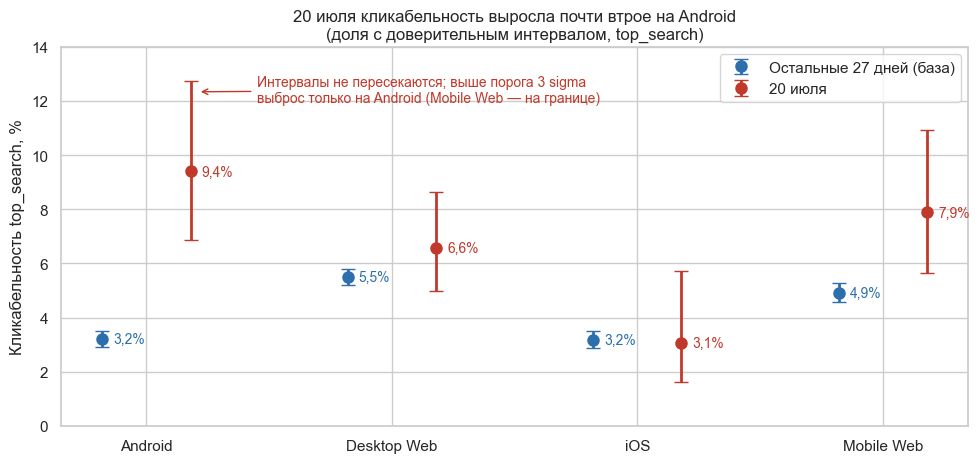

In [342]:
q_daily = '''
SELECT
    i.event_date,
    i.platform,
    COUNT(*) AS impressions,
    COUNT(c.click_id) AS clicks,
    COUNT(r.response_id) AS responses
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
LEFT JOIN responses r ON r.click_id = c.click_id
WHERE i.product = 'top_search'
  AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2
ORDER BY 1, 2
'''
daily = sql(q_daily)
daily["ctr"] = daily["clicks"] / daily["impressions"]
print("строк (дней × платформ):", len(daily), "| дней:", daily.event_date.nunique())

# Основа - все остальные дни, день проверки - 20.07
rows = []
for p in PLATFORMS:
    d = daily[daily.platform == p]
    base = d[d.event_date != SPIKE]
    day = d[d.event_date == SPIKE].iloc[0]
    b_k, b_n = base.clicks.sum(), base.impressions.sum()
    lo_b, hi_b = wilson_ci(b_k, b_n)
    lo_d, hi_d = wilson_ci(day.clicks, day.impressions)
    mu, sd = base.ctr.mean(), base.ctr.std()
    rows.append({
        "платформа": p,
        "база CTR": b_k / b_n, "база lo": lo_b, "база hi": hi_b,
        "20.07 CTR": day.ctr, "20.07 lo": lo_d, "20.07 hi": hi_d,
        "клики 20.07": int(day.clicks), "показы 20.07": int(day.impressions),
        "ожидали кликов": day.impressions * b_k / b_n,
        "порог (среднее+3 sigma)": mu + 3 * sd,
        "z (дневной sigma)": (day.ctr - mu) / sd,
        "p (биномиальный)": stats.binom.sf(day.clicks - 1, day.impressions, b_k / b_n),
        "ДИ не пересекаются": bool(lo_d > hi_b),
        "выше порога 3 sigma": bool(day.ctr > mu + 3 * sd),
    })
plat = pd.DataFrame(rows)
show = plat.copy()
# ИСПРАВЛЕНО: в последнем названии добавлен пробел перед sigma, как в словаре выше
for c in ["база CTR", "база lo", "база hi", "20.07 CTR", "20.07 lo", "20.07 hi", "порог (среднее+3 sigma)"]:
    show[c] = show[c].map(lambda x: pct(x, 2))
show["ожидали кликов"] = show["ожидали кликов"].round(1)
show["z (дневной sigma)"] = show["z (дневной sigma)"].round(1)
show["p (биномиальный)"] = show["p (биномиальный)"].map(lambda x: f"{x:.1e}")
display(show.set_index("платформа"))

# ГРАФИК 1: доля с доверительным интервалом
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(PLATFORMS))
w = 0.18
for j, (lab, c, k) in enumerate([("Остальные 27 дней (база)", BLUE, "база"), ("20 июля", RED, "20.07")]):
    y = plat[f"{k} CTR"].values * 100
    lo = (plat[f"{k} CTR"] - plat[f"{k} lo"]).values * 100
    hi = (plat[f"{k} hi"] - plat[f"{k} CTR"]).values * 100
    xs = x + (j - 0.5) * 2 * w
    ax.errorbar(xs, y, yerr=[lo, hi], fmt="o", color=c, capsize=5, lw=2, ms=8, label=lab)
    for xi, yi, hi_i in zip(xs, y, hi):
        ax.text(xi + 0.045, yi, f"{yi:.1f}%".replace(".", ","), color=c, fontsize=10, va="center", ha="left")
a = plat[plat["платформа"] == "ANDROID"].iloc[0]
ax.annotate("Интервалы не пересекаются; выше порога 3 sigma\nвыброс только на Android (Mobile Web — на границе)",
            xy=(w + 0.03, a["20.07 hi"] * 100 - 0.4), xytext=(0.45, 12.4), fontsize=10, color=RED,
            arrowprops=dict(arrowstyle="->", color=RED), ha="left", va="center")
ax.set_xticks(x)
ax.set_xticklabels(["Android", "Desktop Web", "iOS", "Mobile Web"])
ax.set_ylabel("Кликабельность top_search, %")
ax.set_ylim(0, 14)
ax.set_title("20 июля кликабельность выросла почти втрое на Android\n(доля с доверительным интервалом, top_search)", fontsize=12)
ax.legend(loc="upper right")
plt.tight_layout()
fig.savefig("chart1_ci.png", dpi=150)
plt.show()

**Что видно.** На Android 20.07 кликабельность 9,4% (интервал 6,9–12,7%) против 3,2% (2,9–3,5%) в остальные дни. Интервалы не пересекаются, лишних кликов около 24. На Desktop Web и iOS отличия нет. Mobile Web выше нормы (7,9% против 4,9%), но граница значимости там пограничная: при восьми сравнениях такую разницу ещё можно объяснить шумом.

## 5. Выброс на фоне нормы: распределение дневной кликабельности 

Один день можно принять за шум. Смотрим, насколько Android 20.07 далеко от обычного разброса: боксплот дневной кликабельности остальных дней, точки отдельных дней и красный ромб для 20.07. Пунктир — порог "среднее + $3\sigma$".

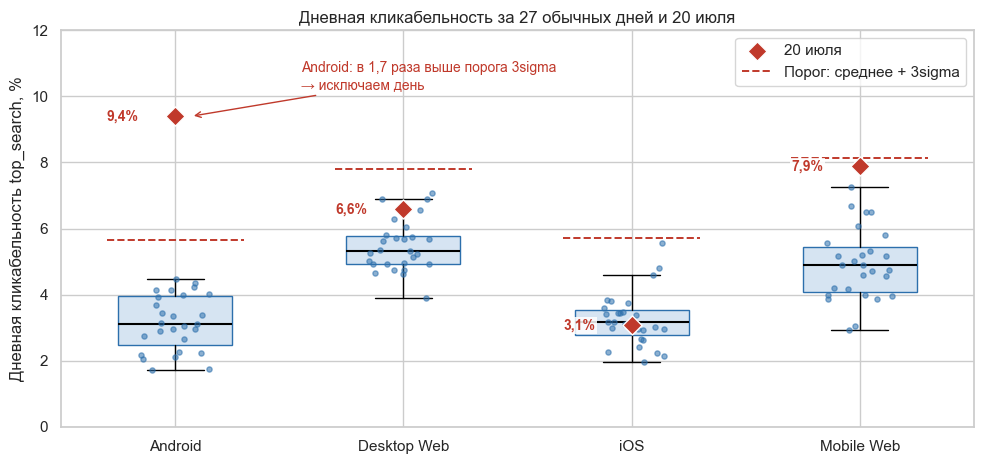

Android, остальные 27 дней: от 1.70% до 4.47%, среднее 3.15%, sigma 0.84%
Порог среднее + 3sigma = 5.66%; 20.07 = 9.40% (в 2.1 раза выше максимума обычных дней)
Отклонение 20.07 от нормы = 5.1 типичных отклонений


In [343]:
fig, ax = plt.subplots(figsize=(10, 4.8))
rng = np.random.default_rng(7)
labels = {"ANDROID": "Android", "DESKTOP_WEB": "Desktop Web", "IOS": "iOS", "MOBILE_WEB": "Mobile Web"}
data = [daily[(daily.platform == p) & (daily.event_date != SPIKE)].ctr.values * 100 for p in PLATFORMS]
bp = ax.boxplot(data, positions=range(len(PLATFORMS)), widths=0.5, showfliers=False, patch_artist=True,
                medianprops=dict(color="black", lw=1.5))
for b in bp["boxes"]:
    b.set(facecolor="#D6E4F2", edgecolor=BLUE)
for i, d in enumerate(data):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(d)), d, s=14, color=BLUE, alpha=0.55, zorder=3)
for i, p in enumerate(PLATFORMS):
    r = plat[plat["платформа"] == p].iloc[0]
    ax.scatter(i, r["20.07 CTR"] * 100, marker="D", s=95, color=RED, zorder=5, edgecolor="white",
               label="20 июля" if i == 0 else None)
    ax.hlines(r["порог (среднее+3 sigma)"] * 100, i - 0.3, i + 0.3, colors=RED, linestyles="--", lw=1.4,
              label="Порог: среднее + 3sigma" if i == 0 else None)
    ax.text(i - 0.16, r["20.07 CTR"] * 100, f"{r['20.07 CTR'] * 100:.1f}%".replace(".", ","),
            color=RED, fontsize=10, va="center", ha="right", fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2))
ratio = plat.iloc[0]["20.07 CTR"] / plat.iloc[0]["порог (среднее+3 sigma)"]
ax.annotate(f"Android: в {ratio:.1f} раза выше порога 3sigma\n→ исключаем день".replace(".", ","),
            xy=(0.07, plat.iloc[0]["20.07 CTR"] * 100), xytext=(0.55, 10.6), fontsize=10, color=RED,
            arrowprops=dict(arrowstyle="->", color=RED), va="center")
ax.set_xticks(range(len(PLATFORMS)))
ax.set_xticklabels([labels[p] for p in PLATFORMS])
ax.set_ylabel("Дневная кликабельность top_search, %")
ax.set_ylim(0, 12)
ax.set_title("Дневная кликабельность за 27 обычных дней и 20 июля", fontsize=12)
ax.legend(loc="upper right")
plt.tight_layout()
fig.savefig("chart2_distribution.png", dpi=150)
plt.show()

a = plat.iloc[0]
others = daily[(daily.platform == "ANDROID") & (daily.event_date != SPIKE)].ctr
print(f"Android, остальные 27 дней: от {pct(others.min(), 2)} до {pct(others.max(), 2)}, среднее {pct(others.mean(), 2)}, sigma {pct(others.std(), 2)}")
print(f"Порог среднее + 3sigma = {pct(a['порог (среднее+3 sigma)'], 2)}; 20.07 = {pct(a['20.07 CTR'], 2)} "
      f"(в {a['20.07 CTR'] / others.max():.1f} раза выше максимума обычных дней)")
mad_z = (a["20.07 CTR"] - others.median()) / (1.4826 * np.median(np.abs(others - others.median())))
print(f"Отклонение 20.07 от нормы = {mad_z:.1f} типичных отклонений")

**Что видно.** Самый высокий обычный день на Android — около 4,5%, порог $3\sigma$ — около 5,7%, а 20.07 — 9,4%. Отклонение 20.07 от нормы около 5.1 типичных отклонений. Это не шум, а выброс вне диапазона нормы.

## 6. Ошибка трекинга или реальный эффект?

Выброс есть. Теперь проверяем, на что он похож: локален ли он по платформе, затрагивает ли все продукты и сегменты, держится ли на следующий день, вырос ли отклик.

In [344]:
A = "ANDROID"
a_d = daily[daily.platform == A].set_index("event_date")

# Тот же день: другой продукт на Android
q_boost = '''
SELECT i.event_date, COUNT(*) AS impressions, COUNT(c.click_id) AS clicks
FROM impressions i LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_boost' AND i.platform = 'ANDROID'
GROUP BY 1
'''
boost = sql(q_boost)
boost["ctr"] = boost.clicks / boost.impressions
b_base = boost[boost.event_date != SPIKE]
b_day = boost[boost.event_date == SPIKE].iloc[0]
b_p = stats.binom.sf(b_day.clicks - 1, b_day.impressions, b_base.clicks.sum() / b_base.impressions.sum())

# Сегменты на Android, top_search
q_seg = '''
SELECT i.segment,
       i.event_date = '2026-07-20' AS is_spike_day,
       COUNT(*) AS impressions, COUNT(c.click_id) AS clicks
FROM impressions i LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_search' AND i.platform = 'ANDROID'
  AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2
'''
seg = sql(q_seg)
seg_rows = []
for s in ["SMB", "Large", "Premium"]:
    base = seg[(seg.segment == s) & (~seg.is_spike_day)].iloc[0]
    day = seg[(seg.segment == s) & (seg.is_spike_day)].iloc[0]
    lo, hi = wilson_ci(day.clicks, day.impressions)
    seg_rows.append({"сегмент": s, "база CTR": pct(base.clicks / base.impressions),
                     "20.07 клики/показы": f"{int(day.clicks)}/{int(day.impressions)}",
                     "20.07 CTR": pct(day.clicks / day.impressions), "ДИ 20.07": f"{pct(lo)}–{pct(hi)}",
                     "выше базы": day.clicks / day.impressions > base.clicks / base.impressions})
seg_tbl = pd.DataFrame(seg_rows)

# Держится ли на следующий день
nxt = a_d.loc["2026-07-18":"2026-07-23", ["impressions", "clicks", "ctr"]].copy()
nxt["ctr"] = nxt.ctr.map(lambda x: pct(x, 2))

# Отклики: конверсия клик -> отклик и отклики на показ
base_a = a_d.drop(SPIKE)
cvr_base = base_a.responses.sum() / base_a.clicks.sum()
d20 = a_d.loc[SPIKE]
cvr_20 = d20.responses / d20.clicks
rr_base = base_a.responses.sum() / base_a.impressions.sum()
rr_20 = d20.responses / d20.impressions
rr_lo, rr_hi = wilson_ci(d20.responses, d20.impressions)

# Отчет за день product_daily: видно ли всплеск?
pdl = product_daily[(product_daily["product"] == "top_search") & (product_daily.event_date >= "2026-07-15")]
pdl = pdl.groupby("event_date")[["impressions", "clicks", "net_spend"]].sum()
pdl["ctr"] = pdl.clicks / pdl.impressions
others_pd = pdl.drop(SPIKE).ctr
z_pd = (pdl.loc[SPIKE, "ctr"] - others_pd.mean()) / others_pd.std()
share_android = impressions[(impressions["product"] == "top_search") & (impressions.event_date == SPIKE)].platform.eq("ANDROID").mean()
expected_lift = share_android * (plat.iloc[0]["20.07 CTR"] - plat.iloc[0]["база CTR"])
expected_z = expected_lift / others_pd.std()

# Деньги: расход 20.07 против обычного
spend = product_daily[product_daily.event_date >= "2026-07-15"].groupby(["event_date", "product"]).net_spend.sum().unstack()
spend_dev = spend.loc[SPIKE] / spend.drop(SPIKE).mean() - 1

print("(1) top_boost на Android 20.07:", f"{int(b_day.clicks)}/{int(b_day.impressions)} = {pct(b_day.ctr)} против {pct(b_base.clicks.sum() / b_base.impressions.sum())}, p = {b_p:.1e}")
print("\n(2) Сегменты Android, top_search:"); display(seg_tbl)
print("(3) Соседние дни, Android, top_search:"); display(nxt)
print(f"(4) Конверсия клик → отклик: 20.07 {int(d20.responses)}/{int(d20.clicks)} = {pct(cvr_20)} против {pct(cvr_base)}")
print(f" Отклики на показ: 20.07 {pct(rr_20, 2)} (ДИ {pct(rr_lo, 2)}–{pct(rr_hi, 2)}) против {pct(rr_base, 2)}")
print(f" Откликов 20.07 всего {int(d20.responses)}: по ним нельзя отличить сбой от реального эффекта.")
print("(5) Сверка с дневным отчетом product_daily")
print(f" CTR 20.07 в отчете: {pct(pdl.loc[SPIKE, 'ctr'], 2)}. Это обычный уровень: отклонение от остальных дней после 15.07 всего {z_pd:.2f} сигмы.")
print(f" Если бы рост на Android был настоящим (доля Android в показах {pct(share_android, 0)}), общий CTR вырос бы примерно на {expected_lift * 100:.1f} ")
print(" В отчете за день такого скачка нет: всплеск виден только в сырых данных.")
print(f"(6) Расход 20.07 по сравнению с обычным днём после запуска: top_search {spend_dev['top_search'] * 100:+.1f}%, top_boost {spend_dev['top_boost'] * 100:+.1f}%.")
print(" Обычный дневной разброс расхода около 2%, значит, в тот день расход не изменился.")

(1) top_boost на Android 20.07: 29/252 = 11.5% против 4.4%, p = 3.1e-06

(2) Сегменты Android, top_search:


,сегмент,база CTR,20.07 клики/показы,20.07 CTR,ДИ 20.07,выше базы
0,SMB,3.2%,20/210,9.5%,6.2%–14.3%,True
1,Large,3.2%,12/111,10.8%,6.3%–18.0%,True
2,Premium,3.4%,4/62,6.5%,2.5%–15.4%,True


(3) Соседние дни, Android, top_search:


,impressions,clicks,ctr
event_date,,,
2026-07-18,371,11,2.96%
2026-07-19,362,11,3.04%
2026-07-20,383,36,9.40%
2026-07-21,400,7,1.75%
2026-07-22,362,15,4.14%
2026-07-23,352,6,1.70%


(4) Конверсия клик → отклик: 20.07 4/36 = 11.1% против 14.2%
 Отклики на показ: 20.07 1.04% (ДИ 0.41%–2.65%) против 0.45%
 Откликов 20.07 всего 4: по ним нельзя отличить сбой от реального эффекта.
(5) Сверка с дневным отчетом product_daily
 CTR 20.07 в отчете: 4.56%. Это обычный уровень: отклонение от остальных дней после 15.07 всего -0.06 сигмы.
 Если бы рост на Android был настоящим (доля Android в показах 21%), общий CTR вырос бы примерно на 1.3 
 В отчете за день такого скачка нет: всплеск виден только в сырых данных.
(6) Расход 20.07 по сравнению с обычным днём после запуска: top_search -0.2%, top_boost +1.6%.
 Обычный дневной разброс расхода около 2%, значит, в тот день расход не изменился.


### Чувствительность к выбору базы

Вывод не должен зависеть от того, с чем сравниваем. Считаем лишние клики и вероятность такого дня при трёх вариантах базового периода.

In [345]:
a_all = a_d.reset_index()
variants = {
    "все остальные дни (1–28, без 20.07)": a_all[a_all.event_date != SPIKE],
    "до запуска (1–14.07)": a_all[a_all.event_date < "2026-07-15"],
    "после запуска (15–28.07, без 20.07)": a_all[(a_all.event_date >= "2026-07-15") & (a_all.event_date != SPIKE)],
}
sens = []
for name, base in variants.items():
    p0 = base.clicks.sum() / base.impressions.sum()
    sens.append({"база": name, "дней": len(base), "CTR базы": pct(p0, 2),
                 "ожидали кликов": round(d20.impressions * p0, 1),
                 "лишних кликов": round(d20.clicks - d20.impressions * p0, 1),
                 "p (биномиальный)": f"{stats.binom.sf(d20.clicks - 1, d20.impressions, p0):.1e}"})
display(pd.DataFrame(sens))

,база,дней,CTR базы,ожидали кликов,лишних кликов,p (биномиальный)
0,"все остальные дни (1–28, без 20.07)",27,3.19%,12.2,23.8,1.3e-08
1,до запуска (1–14.07),14,3.33%,12.8,23.2,3.7e-08
2,"после запуска (15–28.07, без 20.07)",13,2.95%,11.3,24.7,1.6e-09


### Бонус: связь с расходом top_search и top_boost после 15 июля

Если всплеск связан с запуском top_boost, он должен проявиться в динамике расхода. Сравним недельный расход до и после 15.07 и посмотрим на расход вокруг 20.07.

In [346]:
pdl_all = product_daily.copy()
pdl_all["event_date"] = pd.to_datetime(pdl_all["event_date"])
pdl_all["период"] = period_flag(pdl_all["event_date"], "2026-07-15", "до 15.07", "после 15.07")
weekly = (pdl_all.groupby(["период", "product"]).net_spend.sum() / 4).unstack()          # по 4 недели в каждом периоде
pre_s = weekly.loc["до 15.07", "top_search"]
post_s, post_b = weekly.loc["после 15.07", "top_search"], weekly.loc["после 15.07", "top_boost"]
bonus = pd.DataFrame({
    "расход в неделю, млн": {"top_search до": pre_s / 1e6, "top_search после": post_s / 1e6,
                              "top_boost после": post_b / 1e6, "всего после": (post_s + post_b) / 1e6},
    "изменение к top_search до": {"top_search до": "—", "top_search после": f"{(post_s / pre_s - 1) * 100:+.1f}%",
                                   "top_boost после": "—", "всего после": f"{((post_s + post_b) / pre_s - 1) * 100:+.1f}%"},
}).round(2)
display(bonus)

# Динамика вокруг 20.07 и ступень 15.07
daily_spend = pdl_all.groupby(["event_date", "product"]).net_spend.sum().unstack().fillna(0) / 1e3
print("Дневной расход, тыс.:"); display(daily_spend.loc["2026-07-13":"2026-07-23"].round(0))

# Кликабельность Android до/после запуска (сырые события, без 20.07)
a_pre = a_all[a_all.event_date < "2026-07-15"]
a_post = a_all[(a_all.event_date >= "2026-07-15") & (a_all.event_date != SPIKE)]
print(f"Кликабельность Android top_search: до запуска {pct(a_pre.clicks.sum() / a_pre.impressions.sum(), 2)}, после (без 20.07) {pct(a_post.clicks.sum() / a_post.impressions.sum(), 2)}")

,"расход в неделю, млн",изменение к top_search до
top_search до,4.82,—
top_search после,4.01,-16.8%
top_boost после,1.43,—
всего после,5.44,+12.9%


Дневной расход, тыс.:


product,top_boost,top_search
event_date,,
2026-07-13,0.0,714.0
2026-07-14,0.0,685.0
2026-07-15,206.0,596.0
2026-07-16,205.0,580.0
2026-07-17,210.0,574.0
2026-07-18,210.0,587.0
2026-07-19,204.0,573.0
2026-07-20,208.0,572.0
2026-07-21,204.0,563.0


Кликабельность Android top_search: до запуска 3.33%, после (без 20.07) 2.95%


**Вывод.** Расход top_search упал на 16,8% (с 4,82 до 4,01 млн в неделю) и проседает с 15.07, то есть с запуска top_boost, а не с 20.07. Суммарный расход вырос на 12,9% (порог заказчика +10% выполнен, а просадка top_search больше порога −15%). 20.07 расход обоих продуктов не отличается от обычного, кликабельность Android после запуска не выросла (3% против 3,3% до). Вывод: всплеск 20.07 не связан с каннибализацией и динамикой расхода.

## 7. Итог

In [347]:
def num(x, digits=1, sign=False):
    return f"{x:{'+' if sign else ''}.{digits}f}".replace(".", ",")


a = plat.iloc[0]
excess = a["клики 20.07"] - a["ожидали кликов"]
mw = plat[plat["платформа"] == "MOBILE_WEB"].iloc[0]
next_day = a_d.loc["2026-07-21", "ctr"]

print(one_pager(
    decision=(
        "Скорее всего, это ошибка учёта кликов, а не настоящий рост интереса. "
        "Формат показа top_search на Android не меняем."
    ),
    context=(
        f"20 июля на Android кликали в {pct(a['20.07 CTR'])} показов top_search вместо обычных {pct(a['база CTR'])}. "
    ),
    what_done=(
        "Сравнили 20 июля с остальными 27 днями, проверили данные на дубли и пропуски, "
        "посмотрели платформы, продукты, сегменты, отклики и расход."
    ),
    result=(
        f"1) Всплеск не случайный: {int(a['клики 20.07'])} кликов вместо ожидаемых {a['ожидали кликов']:.0f}.\n"
        f"2) Похоже на сбой учёта: вырос только Android, причём оба продукта и все сегменты; "
        f"на следующий день кликабельность вернулась к обычной ({pct(next_day, 1)}); число показов не изменилось.\n"
        f"3) Другие данные рост не подтверждают: в общей сводке его нет, расход не изменился, "
        f"доля откликов среди кликнувших не выросла ({pct(cvr_20, 0)} против {pct(cvr_base, 0)}).\n"
        f"4) Бонус: расход top_search упал на {num(abs(post_s / pre_s - 1) * 100)}% с 15.07 из-за запуска top_boost, "
        f"а суммарный расход вырос на {num(((post_s + post_b) / pre_s - 1) * 100)}%. С всплеском 20.07 это не связано."
    ),
    limits=(
        "Нет точного времени и версии приложения: вывод вероятный. "
        f"Откликов в тот день всего {int(d20.responses)}, этого мало для выводов. "
    ),
    action=(
        "1) Не учитывать Android за 20.07 в расчётах кликабельности. "
        "2) Попросить команду Android проверить, что происходило с записью кликов 20.07. "
        "3) Если там всё чисто — искать настоящую причину (push, рассылка, баннер). "
    ),
))

ИТОГОВАЯ СПРАВКА

Решение:
Скорее всего, это ошибка учёта кликов, а не настоящий рост интереса. Формат показа top_search на Android не меняем.

Контекст:
20 июля на Android кликали в 9.4% показов top_search вместо обычных 3.2%. 

Что сделали:
Сравнили 20 июля с остальными 27 днями, проверили данные на дубли и пропуски, посмотрели платформы, продукты, сегменты, отклики и расход.

Результат:
1) Всплеск не случайный: 36 кликов вместо ожидаемых 12.
2) Похоже на сбой учёта: вырос только Android, причём оба продукта и все сегменты; на следующий день кликабельность вернулась к обычной (1.8%); число показов не изменилось.
3) Другие данные рост не подтверждают: в общей сводке его нет, расход не изменился, доля откликов среди кликнувших не выросла (11% против 14%).
4) Бонус: расход top_search упал на 16,8% с 15.07 из-за запуска top_boost, а суммарный расход вырос на 12,9%. С всплеском 20.07 это не связано.

Ограничения:
Нет точного времени и версии приложения: вывод вероятный. Откликов в тот ден

## 8. Ограничения

- **Нет временных меток и версии приложения.** Нельзя показать, что клики сгруппированы в минутах или идут с одной версии. Это основной способ подтвердить сбой.
- **Отклики не помогают.** За день на Android всего 4 отклика. Данных слишком мало, чтобы различить.
- **Выборка.** Сырые события — около 1% показов и 0,4% откликов витрины. Масштаб и конверсии из двух источников не совпадают, абсолютные цифры конверсии сравнивать нельзя.
- **Витрина без платформ.** В `product_daily` нет разреза по платформам, поэтому нельзя прямо проверить Android в агрегате, только косвенно.
- **Mobile Web.** Тоже выше нормы 20.07. После поправки на множественные сравнения граница значимости: возможно, затронуты и мобильные веб-клиенты.
- **Неизвестные причины.** Не знаем про релиз, рассылку, push-кампанию, баннер или маркетинговую активность на 20.07: реальный эффект поэтому полностью не исключён.